# 06 — Demand transfer: where does a product's demand go when it is removed? (cereal)

**Pipeline notebook:** 06 (work-plan step 5 of 10) · **Data:** cereal, estimation weeks 1–75 · **Models:** fitted in notebook 04, not refitted

For each of the 207 **core** alternatives (pooled tail alternatives are never removed), the notebook removes it from every week's choice set and recomputes both stages of the model:

- **Stage 1 (which product):** the removed product's share is redistributed over the products still available.
- **Stage 2 (whether to buy cereal):** the category becomes slightly less attractive, so some shoppers buy no cereal that week. That demand is **lost**.

This is done separately for each segment, then added up. The pooled and placebo models are run the same way, so step 6 can compare removal lists built from each.

**Why weeks 1–75?** Removal decisions are simulated with the information a retailer would have had. Holdout weeks stay reserved for the RQ1 test (notebook 05).

**Units.** Demand is in expected *purchase occasions* (household-weeks in which the product is the main cereal bought). Revenue converts each occasion at that product's average spend per occasion in weeks 1–75.

**Known model property (state it in the thesis).** Within one segment, the multinomial logit sends displaced demand to the other products in proportion to their shares; it does not know that, say, two kids' cereals are closer substitutes. Differences in where demand goes therefore come from the segments, which is exactly what RQ2 tests.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUTS = Path("modelling_inputs_dunnhumby")
SEGS   = Path("step7_outputs")
PARAMS = Path("outputs/choice_models/model_params.json")
OUT    = Path("outputs/demand_transfer"); OUT.mkdir(parents=True, exist_ok=True)
CAT, NSEG = "cereal", 4

P = json.load(open(PARAMS)); EST_END = P["estimation_weeks"][1]
occ   = pd.read_parquet(INPUTS / f"choice_occasions_{CAT}.parquet")
aw    = pd.read_parquet(INPUTS / f"alt_week_{CAT}.parquet")
alts  = pd.read_parquet(INPUTS / f"alternatives_{CAT}.parquet")
lines = pd.read_parquet(INPUTS / f"choice_lines_{CAT}.parquet")
segs  = pd.read_parquet(SEGS / "household_segments.parquet")[["household_key", "segment", "segment_placebo"]]
est = occ[occ.week_no <= EST_END].merge(segs, on="household_key", how="inner")
print(f"Estimation occasions used for the simulation: {len(est):,} (households {est.household_key.nunique():,})")

Estimation occasions used for the simulation: 83,632 (households 2,039)


## 1. Rebuild the fitted utilities (same code as notebooks 04 and 05)

In [2]:
alt_ids = P["alt_ids"]; J = len(alt_ids); idx = {a: i for i, a in enumerate(alt_ids)}
assert sorted(aw.alt_id.unique()) == alt_ids
REF = idx[P["reference_alt"]]; asc_cols = [i for i in range(J) if i != REF]
aw["j"] = aw.alt_id.map(idx); NW = int(aw.week_no.max())
def grid(col):
    g = np.zeros((J, NW + 1)); g[aw.j, aw.week_no] = aw[col].fillna(0).values; return g
AVAIL = np.zeros((J, NW + 1), bool); AVAIL[aw.j, aw.week_no] = aw.available.values
PRICE, DISC, DISP = grid("price"), grid("disc_depth"), grid("display_share")
A_ = alts.set_index("alt_id").loc[alt_ids]
PL, IS_TAIL = A_.is_private.values.astype(float), A_.is_tail.values

def design(A, w, s, segmented):
    asc = np.zeros((len(A), J - 1)); pos = {c: k for k, c in enumerate(asc_cols)}
    for r, a in enumerate(A):
        if a != REF: asc[r, pos[a]] = 1
    X = np.column_stack([PRICE[A, w], DISC[A, w], DISP[A, w]])
    if not segmented: return np.hstack([asc, X])
    B = np.zeros((len(A), NSEG * 3)); B[:, 3 * s:3 * s + 3] = X
    Q = np.zeros((len(A), NSEG - 1))
    if s > 0: Q[:, s - 1] = PL[A]
    return np.hstack([asc, B, Q])

def month(w): return int(((w - 1) // 4.35) % 12)

# Revenue per purchase occasion for each alternative (weeks 1-75)
rev = lines[lines.week_no <= EST_END].groupby("alt_id").spend.mean().reindex(alt_ids)
REV = rev.fillna(rev.median()).values
print(f"Average spend per purchase occasion: median ${np.median(REV):.2f} (range ${REV.min():.2f}-${REV.max():.2f})")

Average spend per purchase occasion: median $3.05 (range $1.05-$5.69)


## 2. Simulate every removal

For week *w* and segment *s* with *N* shopping occasions, buying probability *b* and product shares *p*:

- base demand of product *j* = *N · b · p_j*
- after removing *j*: attractiveness drops to IV + log(1 − *p_j*), giving a new buying probability *b′*; each remaining product *k* gets share *p_k* / (1 − *p_j*)
- demand moved to *k* = *N* · [*b′ · p_k* / (1 − *p_j*) − *b · p_k*]
- lost demand = base demand of *j* − everything moved to other products

All 207 removals are computed at once per week and segment (closed form, no loop over products).

In [3]:
CORE = np.where(~IS_TAIL)[0]
def simulate(name):
    m = P["models"][name]; segm, col = m["segmented"], m["segment_column"]
    th = np.array(m["stage1_theta"]); b2 = m["stage2_params"]
    counts = est.groupby(["week_no", col]).size() if segm else est.groupby("week_no").size()
    base = np.zeros((NSEG, J)); moved = np.zeros((NSEG, J, J))      # moved[s, j_removed, k_receiving]
    for key, N in counts.items():
        w, s = (key[0], int(key[1]) - 1) if segm else (key, 0)
        A = np.where(AVAIL[:, w])[0]
        V = design(A, w, s, segm) @ th; iv = V.max() + np.log(np.exp(V - V.max()).sum()); p = np.exp(V - iv)
        k = f" | seg {s + 1}" if segm else ""
        c0 = b2[f"const{k}"] + (b2.get(f"month_{month(w)}", 0.0) if month(w) > 0 else 0.0); lam = b2[f"attractiveness{k}"]
        b = 1 / (1 + np.exp(-(c0 + lam * iv)))
        b_new = 1 / (1 + np.exp(-(c0 + lam * (iv + np.log1p(-p)))))     # buying probability after removing each product in A
        base[s, A] += N * b * p
        M = N * (np.outer(b_new / (1 - p), p) - b * p[None, :])          # rows: removed product, cols: receiving product
        np.fill_diagonal(M, 0.0)
        moved[s][np.ix_(A, A)] += M
    return base, moved

SIM = {name: simulate(name) for name in P["models"]}

## 3. Check that the flows add up

In [4]:
for name, (base, moved) in SIM.items():
    tot_base = base.sum(0); tot_moved = moved.sum(0).sum(1)
    assert (moved[:, CORE][:, :, :] >= -1e-9).all(), "negative transfer found"
    assert (tot_moved[CORE] <= tot_base[CORE] + 1e-9).all(), "more demand moved than existed"
    print(f"{name:8s} total base purchases {tot_base.sum():8.1f} vs observed in weeks 1-75 {int(est.bought.sum()):,} | "
          f"retained share over all core removals {tot_moved[CORE].sum() / tot_base[CORE].sum():.3f}")

pooled   total base purchases  15904.0 vs observed in weeks 1-75 15,904 | retained share over all core removals 0.796
segment  total base purchases  15904.0 vs observed in weeks 1-75 15,904 | retained share over all core removals 0.789
placebo  total base purchases  15904.0 vs observed in weeks 1-75 15,904 | retained share over all core removals 0.800


## 4. Transfer summary per removed product

In [5]:
def summary(name):
    base, moved = SIM[name]; segm = P["models"][name]["segmented"]; rows = []
    groups = [("all", slice(None))] + ([(f"seg {s + 1}", s) for s in range(NSEG)] if segm else [])
    for label, sl in groups:
        b = base[sl].sum(0) if label == "all" else base[sl]; mv = moved[sl].sum(0) if label == "all" else moved[sl]
        for j in CORE:
            out = mv[j]; kept = out.sum(); top = int(out.argmax())
            rows.append(dict(model=name, group=label, alt_id=alt_ids[j], private_label=bool(PL[j]),
                             base_purchases=b[j], retained_purchases=kept, lost_purchases=b[j] - kept,
                             retained_share=kept / b[j] if b[j] > 0 else np.nan,
                             base_revenue=b[j] * REV[j], revenue_retained=(out * REV).sum(), revenue_lost=b[j] * REV[j] - (out * REV).sum(),
                             top_destination=alt_ids[top], top_destination_share=out[top] / kept if kept > 0 else np.nan))
    return pd.DataFrame(rows)
summ = pd.concat([summary(n) for n in P["models"]], ignore_index=True)
summ["revenue_lost_share"] = summ.revenue_lost / summ.base_revenue
neg = summ[summ.group == "all"].groupby("model").apply(lambda d: int((d.revenue_lost < 0).sum()))
print("Products whose removal RAISES category revenue (buyers move to pricier products):", neg.to_dict())
summ[summ.group == "all"].groupby("model")[["base_purchases", "retained_share", "revenue_lost_share"]].describe().T.round(3)

Products whose removal RAISES category revenue (buyers move to pricier products): {'placebo': 53, 'pooled': 53, 'segment': 47}


model                     placebo   pooled  segment
base_purchases     count  207.000  207.000  207.000
                   mean    73.028   73.028   73.027
                   std     53.014   53.013   52.989
                   min      7.974    7.969    7.945
                   25%     32.136   32.137   32.118
                   50%     56.985   56.968   57.083
                   75%     96.747   96.726   96.812
                   max    317.571  317.651  316.008
retained_share     count  207.000  207.000  207.000
                   mean     0.800    0.797    0.790
                   std      0.001    0.000    0.007
                   min      0.798    0.795    0.774
                   25%      0.799    0.796    0.784
                   50%      0.800    0.797    0.791
                   75%      0.801    0.797    0.795
                   max      0.802    0.798    0.807
revenue_lost_share count  207.000  207.000  207.000
                   mean     0.110    0.114    0.127
                   std      0.287    0.287    0.262
                   min     -1.368   -1.362   -1.262
                   25%     -0.010   -0.006    0.019
                   50%      0.186    0.190    0.192
                   75%      0.290    0.294    0.287
                   max      0.565    0.567    0.555

## 5. Do segments differ in how much demand they keep?

Retained share of a removed product's demand, by segment (segment model). Each product counts once per segment.

In [6]:
seg_tbl = (summ[(summ.model == "segment") & (summ.group != "all")]
           .groupby("group").apply(lambda d: pd.Series({
               "products": len(d), "base_purchases": d.base_purchases.sum(),
               "retained_share_weighted": d.retained_purchases.sum() / d.base_purchases.sum(),
               "median": d.retained_share.median(), "p10": d.retained_share.quantile(.1), "p90": d.retained_share.quantile(.9)})))
seg_tbl.round(3)

,products,base_purchases,retained_share_weighted,median,p10,p90
group,,,,,,
seg 1,207.0,6179.776,0.856,0.856,0.856,0.856
seg 2,207.0,4037.308,0.814,0.814,0.813,0.815
seg 3,207.0,1719.591,0.934,0.934,0.934,0.935
seg 4,207.0,3179.981,0.551,0.551,0.549,0.553


## 6. Does the segment model change which products look safe to remove?

Each product's lost revenue under the pooled and the segment model (both chain-wide, weeks 1–75). Step 6 builds the actual removal lists; this is a first look at how much the ranking moves.

In [7]:
cmp = (summ[summ.group == "all"].pivot(index="alt_id", columns="model", values="revenue_lost"))
cmp["rank_pooled"] = cmp.pooled.rank(); cmp["rank_segment"] = cmp.segment.rank()
rho = cmp[["pooled", "segment"]].corr(method="spearman").iloc[0, 1]
n_cut = int(round(0.10 * len(CORE)))
low_p, low_s = set(cmp.nsmallest(n_cut, "pooled").index), set(cmp.nsmallest(n_cut, "segment").index)
print(f"Rank correlation of lost revenue, pooled vs segment model: {rho:.3f}")
print(f"Of the {n_cut} products losing least revenue, {len(low_p & low_s)} are the same under both models "
      f"(single-removal ranking; step 6 uses the greedy rule).")
moves = (cmp.rank_segment - cmp.rank_pooled).abs()
print(f"Median rank shift {moves.median():.0f} places; products moving 20+ places: {(moves >= 20).sum()} of {len(cmp)}")

Rank correlation of lost revenue, pooled vs segment model: 0.997
Of the 21 products losing least revenue, 21 are the same under both models (single-removal ranking; step 6 uses the greedy rule).
Median rank shift 2 places; products moving 20+ places: 1 of 207


## 7. Figures

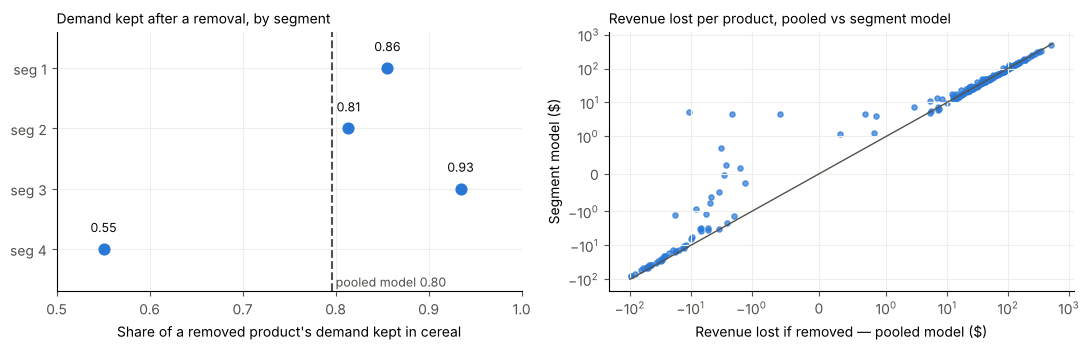

In [8]:
d = summ[(summ.model == "segment") & (summ.group != "all")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
w = seg_tbl.retained_share_weighted.values; y = np.arange(NSEG)
ax.scatter(w, y, s=60, color="#2a78d6", zorder=3)
for yi, wi in zip(y, w): ax.text(wi, yi - 0.28, f"{wi:.2f}", ha="center", fontsize=9, color="#0b0b0b")
pooled_r = summ[(summ.model == "pooled") & (summ.group == "all")]
pooled_w = pooled_r.retained_purchases.sum() / pooled_r.base_purchases.sum()
ax.axvline(pooled_w, color="#52514e", ls="--", lw=1.5); ax.text(pooled_w, NSEG - 0.45, f" pooled model {pooled_w:.2f}", color="#52514e", fontsize=9, va="center")
ax.set_yticks(y, [f"seg {s}" for s in range(1, NSEG + 1)]); ax.set_ylim(NSEG - 0.3, -0.6); ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Share of a removed product's demand kept in cereal"); ax.set_title("Demand kept after a removal, by segment", loc="left", fontsize=10)
ax = axes[1]
ax.scatter(cmp.pooled, cmp.segment, s=14, color="#2a78d6", alpha=0.7)
lim = [min(cmp.pooled.min(), cmp.segment.min()) * 1.05, max(cmp.pooled.max(), cmp.segment.max()) * 1.05]; ax.plot(lim, lim, color="#52514e", lw=1)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Revenue lost if removed — pooled model ($)"); ax.set_ylabel("Segment model ($)")
ax.set_title("Revenue lost per product, pooled vs segment model", loc="left", fontsize=10)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
    a.grid(color="#eeeeec"); a.tick_params(colors="#52514e")
fig.tight_layout(); fig.savefig(OUT / "demand_transfer_overview.png", dpi=150); plt.show()

## 8. Save outputs for step 6

In [9]:
summ.to_csv(OUT / "transfer_summary.csv", index=False)
seg_tbl.to_csv(OUT / "retention_by_segment.csv")
rows = []
for name, (base, moved) in SIM.items():
    segm = P["models"][name]["segmented"]
    for s in (range(NSEG) if segm else [0]):
        jj, kk = np.nonzero(moved[s][CORE] > 1e-9)
        rows.append(pd.DataFrame({"model": name, "segment": (s + 1) if segm else 0, "removed_alt": np.array(alt_ids)[CORE[jj]],
                                  "receiving_alt": np.array(alt_ids)[kk], "purchases_moved": moved[s][CORE[jj], kk]}))
flows = pd.concat(rows, ignore_index=True); flows.to_parquet(OUT / "transfer_flows.parquet", index=False)
pd.DataFrame({"alt_id": alt_ids, "revenue_per_purchase": REV, "is_tail": IS_TAIL, "private_label": PL.astype(bool)}).to_csv(OUT / "alternative_revenue.csv", index=False)
print(f"Flow rows: {len(flows):,}")
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Flow rows: 418,032
Saved:
  alternative_revenue.csv
  demand_transfer_overview.png
  retention_by_segment.csv
  transfer_flows.parquet
  transfer_summary.csv


## 9. What carries into step 6

- `transfer_summary.csv`: for each core product, model and segment, the demand and revenue kept or lost when it alone is removed.
- `transfer_flows.parquet`: the full product-to-product flows, for the greedy removal lists in step 6 (which removes products one at a time and recomputes).
- These are single-product removals. Removing several products at once is not the sum of single removals, which is why step 6 recomputes after each removal.